# Общая настройка

In [411]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Задание 1. Погрешности

Импорт экспериментальных данных

In [412]:
data_1 = pd.read_csv("experimental_data/task_01.csv", encoding='utf-8', index_col=0)
data_1 = data_1.reset_index(drop=True)
data_1

,h_mm,D_mm,d_mm
0,70.00,29.90,25.05
1,69.95,29.95,24.95
2,70.00,30.10,25.05
3,70.05,30.15,24.90
4,70.20,29.95,25.05
5,NaN,29.95,25.00
6,NaN,NaN,24.90
7,NaN,NaN,25.00


## Расчёт погрешности прямых измерений размеров цилиндра
Добавление комментариев к строке (измерение, среднее значение, погрешность и т. д.)

Расчёт среднего значения по формуле $$mean = \frac{\Sigma x}{n}$$ где $x$ - значение измерения, $n$ - количество измерений

In [413]:
data_1['Comment'] = [f'Measure {i}' for i in range(1, len(data_1) + 1)]

h_mean_mm = np.sum(data_1.iloc[:,0])/data_1['h_mm'].count()
D_mean_mm = np.sum(data_1.iloc[:,1])/data_1['D_mm'].count()
d_mean_mm = np.sum(data_1.iloc[:,2])/data_1['d_mm'].count()

data_1.loc[len(data_1)] = {
    'h_mm': np.round(h_mean_mm, 2),
    'D_mm': np.round(D_mean_mm, 2),
    'd_mm': np.round(d_mean_mm, 2),
    'Comment': 'Mean'
}

data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean


Расчёт погрешности округления по формуле $$\Delta x_{пр} = p \frac{h}{2}$$ где p - доверительная вероятность (0.95), h - половина цены деления шкалы прибора (0,05 мм)

In [414]:
p = 0.95
h_mm = 0.05

h_round_mm = np.round(p*h_mm/2,2)
d_round_mm = np.round(p*h_mm/2,2)
D_round_mm = np.round(p*h_mm/2,2)

data_1.loc[len(data_1)] = {
    'h_mm': h_round_mm,
    'D_mm': d_round_mm,
    'd_mm': D_round_mm,
    'Comment': 'Round error'
}
data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean
9,0.02,0.02,0.02,Round error


Расчёт приборной погрешности по формуле: $$\Delta x_{пр} = \frac{2}{3}\delta x$$ где $\delta x$ - приборная погрешность нониусного штангенциркуля с ценой деления 0,05 мм (±0,05 мм)

In [415]:
delta_x_mm = 0.05

h_instrumental_mm = np.round(2/3*delta_x_mm,2)
D_instrumental_mm = np.round(2/3*delta_x_mm,2)
d_instrumental_mm = np.round(2/3*delta_x_mm,2)

data_1.loc[len(data_1)] = {
    'h_mm': h_instrumental_mm,
    'D_mm': D_instrumental_mm,
    'd_mm': d_instrumental_mm,
    'Comment': 'Instrumental error'
}
data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean
9,0.02,0.02,0.02,Round error


Количество измерений

In [416]:
h_n = data_1['h_mm'].count()-3
D_n = data_1['D_mm'].count()-3
d_n = data_1['d_mm'].count()-3

data_1.loc[len(data_1)] = {
    'h_mm': h_n,
    'D_mm': D_n,
    'd_mm': d_n,
    'Comment': 'Number of measures'
}
data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean
9,0.02,0.02,0.02,Round error


Точный расчёт коэффициента Стьюдента (через библиотеку SciPy)

In [417]:
t_h = stats.t.ppf(0.975, df=h_n-1)
t_D = stats.t.ppf(0.975, df=D_n-1)
t_d = stats.t.ppf(0.975, df=d_n-1)

data_1.loc[len(data_1)] = {
    'h_mm': np.round(t_h,2),
    'D_mm': np.round(t_D,2),
    'd_mm': np.round(t_d,2),
    'Comment': "Student's coefficient"
}
data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean
9,0.02,0.02,0.02,Round error


Расчёт случайной погрешности по формуле: $$\Delta x_{сл.} = t\sqrt\frac{\sum_{k=1}^{N}(x_k-\bar{x})^2}{N(N-1)}$$

In [418]:
h_random_mm = np.round(t_h*np.sqrt(np.sum((data_1.iloc[:-5,0]-h_mean_mm)**2)/(h_n*(h_n - 1))), 2)
D_random_mm = np.round(t_D*np.sqrt(np.sum((data_1.iloc[:-5,1]-D_mean_mm)**2)/(D_n*(D_n - 1))), 2)
d_random_mm = np.round(t_d*np.sqrt(np.sum((data_1.iloc[:-5,2]-d_mean_mm)**2)/(d_n*(d_n - 1))), 2)

data_1.loc[len(data_1)] = {
    'h_mm': h_random_mm,
    'D_mm': D_random_mm,
    'd_mm': d_random_mm,
    'Comment': "Random error"
}
data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean
9,0.02,0.02,0.02,Round error


Расчёт полной погрешности по формуле: $$\Delta x_ = \sqrt{(\Delta x_{пр.})^2+(\Delta x_{сл.})^2+(\Delta x_{окр.})^2}$$

In [419]:
h_full_mm = np.round(np.sqrt((h_round_mm)**2 + (h_instrumental_mm)**2 + (h_random_mm)**2), 2)
D_full_mm = np.round(np.sqrt((D_round_mm)**2 + (D_instrumental_mm)**2 + (D_random_mm)**2), 2)
d_full_mm = np.round(np.sqrt((d_round_mm)**2 + (d_instrumental_mm)**2 + (d_random_mm)**2), 2)

data_1.loc[len(data_1)] = {
    'h_mm': h_full_mm,
    'D_mm': D_full_mm,
    'd_mm': d_full_mm,
    'Comment': "Full error"
}
data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean
9,0.02,0.02,0.02,Round error


In [420]:
h_percentage = 100*np.round((h_full_mm/h_mean_mm), 2)
D_percentage = 100*np.round((D_full_mm/D_mean_mm), 2)
d_percentage = 100*np.round((d_full_mm/d_mean_mm), 2)


data_1.loc[len(data_1)] = {
    'h_mm': h_percentage,
    'D_mm': D_percentage,
    'd_mm': d_percentage,
    'Comment': "Percentage error, %"
}
data_1

,h_mm,D_mm,d_mm,Comment
0,70.00,29.90,25.05,Measure 1
1,69.95,29.95,24.95,Measure 2
2,70.00,30.10,25.05,Measure 3
3,70.05,30.15,24.90,Measure 4
4,70.20,29.95,25.05,Measure 5
5,NaN,29.95,25.00,Measure 6
6,NaN,NaN,24.90,Measure 7
7,NaN,NaN,25.00,Measure 8
8,70.04,30.00,24.99,Mean
9,0.02,0.02,0.02,Round error


## Расчёт объёма цилиндра и погрешности определения объёма

Вычислим объём цилиндра и погрешность по формулам: $$V(\bar{h}, \bar{D}, \bar{d}) = \frac{\pi(\bar{D}^2-\bar{d}^2)}{4}\cdot\bar{h}$$
$$\Delta V(\Delta{h}, \Delta{D}, \Delta{d}) = \sqrt{(\frac{\partial V}{\partial h} \cdot \Delta h)^2 + (\frac{\partial V}{\partial D} \cdot \Delta D)^2 + (\frac{\partial V}{\partial d} \cdot \Delta d)^2}$$

Вычисляя частные производные, получим:
$$\frac{\partial V}{\partial h} = \frac{\pi}{4}(D^2 - d^2)$$
$$\frac{\partial V}{\partial D} = \frac{\pi}{2}Dh$$
$$\frac{\partial V}{\partial d} = -\frac{\pi}{2}dh$$

Тогда $$\Delta V(\Delta{h}, \Delta{D}, \Delta{d}) = \sqrt{(\frac{\pi}{4}(D^2 - d^2) \cdot \Delta h)^2 + (\frac{\pi}{2}Dh \cdot \Delta D)^2 + (\frac{\pi}{2}dh \cdot \Delta d)^2}$$

In [421]:
V_mm3 = np.round(np.pi/4*(D_mean_mm**2-d_mean_mm**2)*h_mean_mm,2)
print('Cylinder volume:', V_mm3, 'mm^3')

V_full_mm3 = np.round(np.sqrt((np.pi/4*(D_mean_mm**2-d_mean_mm**2)*h_full_mm)**2 + (np.pi/2*(D_mean_mm*h_mean_mm)*D_full_mm)**2 + (np.pi/2*(d_mean_mm*h_mean_mm)*d_full_mm)**2),2)
print('Full error:', V_full_mm3, 'mm^3')

V_percentage_mm3 = np.round(V_full_mm3/V_mm3,2)
print('Percentage error:', V_percentage_mm3, 'mm^3')

Cylinder volume: 15161.93 mm^3
Full error: 399.77 mm^3
Percentage error: 0.03 mm^3


# Задание 2. Метод наименьших квадратов

Импорт экспериментальных данных

In [422]:
data_2 = pd.read_csv("experimental_data/task_02.csv", encoding='utf-8', index_col=0)
data_2 = data_2.reset_index(drop=True)
data_2

,x,y
0,1.0,45.53
1,3.0,42.81
2,5.0,38.89
3,7.0,35.70
4,9.0,34.30
5,11.0,29.63
6,13.0,25.79
7,15.0,24.24
8,17.0,22.48
9,19.0,19.41


Построение графика

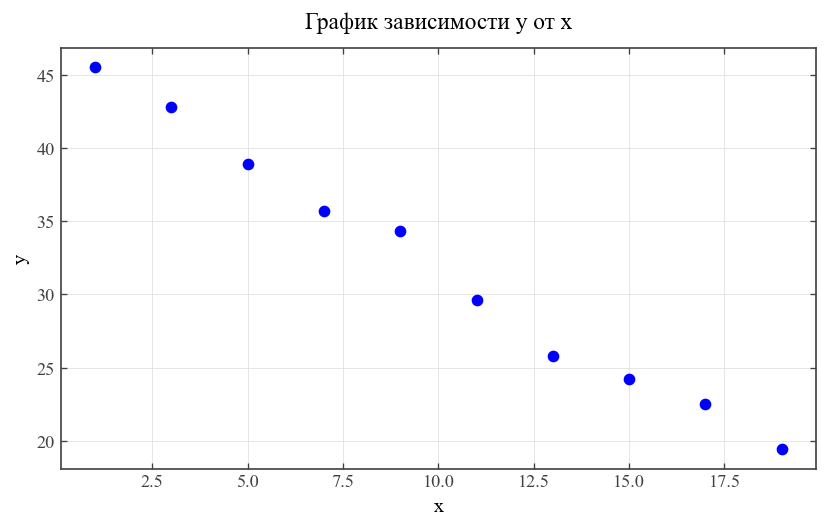

In [423]:
x_data = data_2.iloc[:, 0]
y_data = data_2.iloc[:, 1]

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'stix'

ax.grid(True, which='both', linestyle='-', linewidth=0.5, color='#e2e2e2')
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#404040')
    spine.set_linewidth(1.0)

ax.tick_params(direction='in', top=True, right=True, width=0.8, colors='#404040', labelsize=11)
               
ax.plot(x_data, y_data, 'o', color='blue', label='Данные') 

ax.set_title("График зависимости y от x", fontsize=14, pad=12, fontname='Times New Roman')
ax.set_xlabel("x", fontsize=12, fontname='Times New Roman')
ax.set_ylabel("y", fontsize=12, fontname='Times New Roman')

plt.tight_layout()
plt.show()

Добавление комментариев к строке (измерение, среднее значение, погрешность и т. д.)

Расчёт среднего значения по формуле $$mean = \frac{\Sigma x}{n}$$ где $x$ - значение измерения, $n$ - количество измерений

In [424]:
data_2['Comment'] = [f'Measure {i}' for i in range(1, len(data_2) + 1)]

x_mean = np.sum(data_2.iloc[:,0])/10
y_mean = np.sum(data_2.iloc[:,1])/10

data_2.loc[len(data_2)] = {
    'x': np.round(x_mean, 2),
    'y': np.round(y_mean, 2),
    'Comment': 'Mean'
}

data_2

,x,y,Comment
0,1.0,45.53,Measure 1
1,3.0,42.81,Measure 2
2,5.0,38.89,Measure 3
3,7.0,35.70,Measure 4
4,9.0,34.30,Measure 5
5,11.0,29.63,Measure 6
6,13.0,25.79,Measure 7
7,15.0,24.24,Measure 8
8,17.0,22.48,Measure 9
9,19.0,19.41,Measure 10


Расчёт дисперсии по формулам: $$ S_x^2 = \overline{x^2} - (\overline{x})^2 $$
$$ S_y^2 = \overline{y^2} - (\overline{y})^2 $$

In [425]:
x_squared_mean = np.sum(data_2.iloc[:-1,0]**2)/10
y_squared_mean = np.sum(data_2.iloc[:-1,1]**2)/10

S_x2 = x_squared_mean - x_mean**2
S_y2 = y_squared_mean - y_mean**2

data_2.loc[len(data_2)] = {
    'x': np.round(S_x2, 2),
    'y': np.round(S_y2, 2),
    'Comment': 'Dispersion'
}

data_2

,x,y,Comment
0,1.0,45.53,Measure 1
1,3.0,42.81,Measure 2
2,5.0,38.89,Measure 3
3,7.0,35.70,Measure 4
4,9.0,34.30,Measure 5
5,11.0,29.63,Measure 6
6,13.0,25.79,Measure 7
7,15.0,24.24,Measure 8
8,17.0,22.48,Measure 9
9,19.0,19.41,Measure 10


Расчёт коэффициента ковариации по формуле: $$ R_{xy} = \overline{xy} - \overline{x} \cdot \overline{y} $$

In [426]:
xy_mean = np.sum(data_2.iloc[:-2,0]*data_2.iloc[:-2,1])/10
R_xy = xy_mean - x_mean*y_mean

print('Covariance coefficient:', np.round(R_xy, 2))

Covariance coefficient: -48.5


Расчёт коэффициента стъюдента (с доверительной вероятностью 95%)

In [427]:
t = stats.t.ppf(0.975, df=9)

print("Student's coefficient:", np.round(t, 2))

Student's coefficient: 2.26


Расчёт коэффициента корреляции:
$$r = \frac{R_{xy}}{\sqrt{S_x^2 \cdot S_y^2}}$$

In [428]:
r = R_xy/np.sqrt((S_x2) * (S_y2))

print("Correlation coefficient:", np.round(r, 2))

Correlation coefficient: -1.0


Расчёт коэффициентов a и b по формулам: $$a = \frac{R_{xy}}{S_x^2}$$ $$b = \overline{y}-a\overline{x}$$

In [429]:
a = R_xy/S_x2
b = y_mean - a*x_mean

print("a:", np.round(a, 2))
print("b:", np.round(b, 2))

a: -1.47
b: 46.58


Расчёт погрешностей a и b по формулам: $$\Delta a = t \cdot \sqrt{\frac{1}{n - 2} \cdot \left( \frac{S_y^2}{S_x^2} - a^2 \right)}$$ $$\Delta b = \Delta a \cdot \sqrt{S_x^2 + (\overline{x})^2}$$

In [430]:
Delta_a = t*np.sqrt(1/8*(S_y2/S_x2-a**2))
Delta_b = Delta_a*np.sqrt(S_x2+(x_mean)**2)

print("a:", np.round(a, 2))
print("b:", np.round(b, 2))

a: -1.47
b: 46.58


# Задание 3. МНК для нелинейной зависимости

Импорт экспериментальных данных

In [431]:
data_3 = pd.read_csv("experimental_data/task_03.csv", encoding='utf-8', index_col=0)
data_3

,x,y
1,1.0,1.647
2,2.0,3.947
3,3.0,7.121
4,4.0,12.616
5,5.0,16.622
6,6.0,22.654
7,7.0,28.450
8,8.0,33.670
9,9.0,39.897
10,10.0,47.136


Построение графика

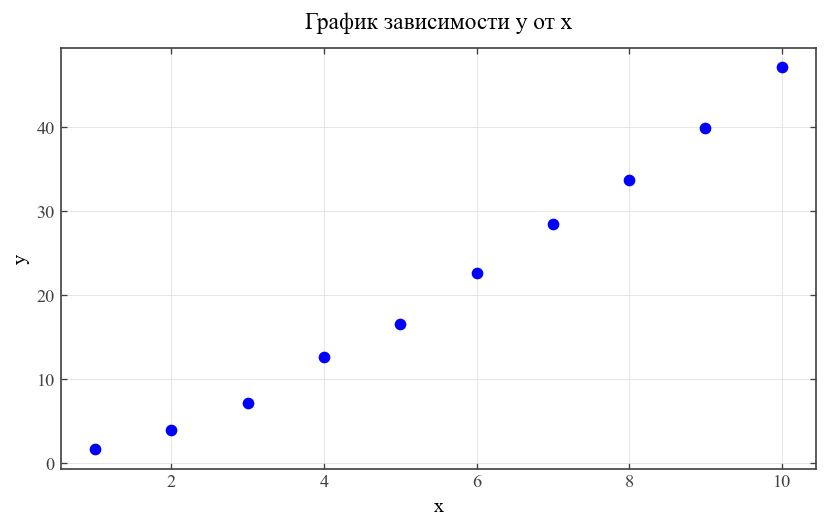

In [432]:
x_data = data_3.iloc[:, 0]
y_data = data_3.iloc[:, 1]

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'stix'

ax.grid(True, which='both', linestyle='-', linewidth=0.5, color='#e2e2e2')
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#404040')
    spine.set_linewidth(1.0)

ax.tick_params(direction='in', top=True, right=True, width=0.8, colors='#404040', labelsize=11)
               
ax.plot(x_data, y_data, 'o', color='blue', label='Данные') 

ax.set_title("График зависимости y от x", fontsize=14, pad=12, fontname='Times New Roman')
ax.set_xlabel("x", fontsize=12, fontname='Times New Roman')
ax.set_ylabel("y", fontsize=12, fontname='Times New Roman')

plt.tight_layout()
plt.show()

Введение замену переменных: $$y = Cx^n \iff \lg y = \lg C + n \lg x \iff Y = AX + B$$ где $A = n, B = \lg C, X = \lg x, Y = \lg y$

In [433]:
data_X = np.log10(data_3.iloc[:, 0])
data_Y = np.log10(data_3.iloc[:, 1])

data_X

1     0.000000
2     0.301030
3     0.477121
4     0.602060
5     0.698970
6     0.778151
7     0.845098
8     0.903090
9     0.954243
10    1.000000
Name: x, dtype: float64

In [434]:
data_Y

1     0.216694
2     0.596267
3     0.852541
4     1.100922
5     1.220683
6     1.355145
7     1.454082
8     1.527243
9     1.600940
10    1.673353
Name: y, dtype: float64

Построение графика

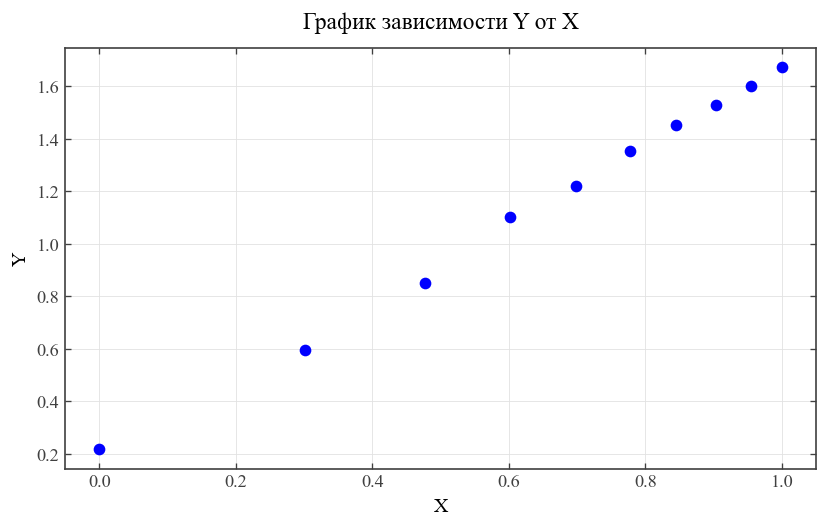

In [435]:
x_data = data_X
y_data = data_Y

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'stix'

ax.grid(True, which='both', linestyle='-', linewidth=0.5, color='#e2e2e2')
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#404040')
    spine.set_linewidth(1.0)

ax.tick_params(direction='in', top=True, right=True, width=0.8, colors='#404040', labelsize=11)
               
ax.plot(x_data, y_data, 'o', color='blue', label='Данные') 

ax.set_title("График зависимости Y от X", fontsize=14, pad=12, fontname='Times New Roman')
ax.set_xlabel("X", fontsize=12, fontname='Times New Roman')
ax.set_ylabel("Y", fontsize=12, fontname='Times New Roman')

plt.tight_layout()
plt.show()

Нахождение коэффициентов A и B (аналогично предыдущей назачи)

In [436]:
x_mean = np.sum(data_X)/10
y_mean = np.sum(data_Y)/10

print('Mean X:', np.round(x_mean, 2))
print('Mean Y:', np.round(y_mean, 2))

x_squared_mean = np.sum(data_X**2)/10
y_squared_mean = np.sum(data_Y**2)/10

S_x2 = x_squared_mean - x_mean**2
S_y2 = y_squared_mean - y_mean**2

print('Dispersion X:', np.round(S_x2, 2))
print('Dispersion Y:', np.round(S_y2, 2))

xy_mean = np.sum(data_X*data_Y)/10
R_xy = xy_mean - x_mean*y_mean

print('Covariance coefficient:', np.round(R_xy, 2))

t = stats.t.ppf(0.975, df=9)

print("Student's coefficient:", np.round(t, 2))

r = R_xy/np.sqrt((S_x2) * (S_y2))

print("Correlation coefficient:", np.round(r, 2))

A = R_xy/S_x2
B = y_mean - A*x_mean

print("A:", np.round(A, 2))
print("B:", np.round(B, 2))

Delta_A = t*np.sqrt(1/8*(S_y2/S_x2-A**2))
Delta_B = Delta_A*np.sqrt(S_x2+(x_mean)**2)

print("Delta A:", np.round(A, 2))
print("Delta B:", np.round(B, 2))

Mean X: 0.66
Mean Y: 1.16
Dispersion X: 0.09
Dispersion Y: 0.2
Covariance coefficient: 0.14
Student's coefficient: 2.26
Correlation coefficient: 1.0
A: 1.49
B: 0.18
Delta A: 1.49
Delta B: 0.18


Нахождение коэффициентов C, n по формулам: $$C = 10^B, n = A$$

In [437]:
C = 10**B
n = A

print("C:", np.round(C, 2))
print("n:", np.round(n, 2))

C: 1.52
n: 1.49


Нахождение погрешностей коэффициентов C, n по формулам: $$\Delta n = \Delta A$$
$$\Delta C = 10^B \cdot \ln 10 \cdot \Delta B = C \cdot \ln 10 \cdot \Delta B$$

In [438]:
Delta_C = C*Delta_B*np.log(10)
Delta_n = Delta_A

print("Delta C:", np.round(Delta_C, 2))
print("Delta n:", np.round(Delta_n, 2))

Delta C: 0.15
Delta n: 0.06
